## Loading the data

In [46]:
import pandas as pd
import numpy as np

from pathlib import Path

DATA_PATH = Path("../data/raw")

orders = pd.read_csv(DATA_PATH / "olist_orders_dataset.csv")

order_items = pd.read_csv(DATA_PATH / "olist_order_items_dataset.csv")

customers = pd.read_csv(DATA_PATH / "olist_customers_dataset.csv")

sellers = pd.read_csv(DATA_PATH / "olist_sellers_dataset.csv")

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11


## Inspecting the data

In [3]:
datasets = {
    "orders": orders,
    "order_items": order_items,
    "customers": customers,
    "sellers": sellers
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"{'=' * 50}")

    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())



Dataset: orders
Rows: 99441
Columns: 8

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data Types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Dataset: order_items
Rows: 112650
Columns: 7

Columns:
['order_id', 'order_item_id', 'product_id', 's

## Inspecting granularity

In [73]:
print(
    "Orders:",
    orders["order_id"].nunique()
)

print(
    "Items:",
    order_items["order_id"].nunique()
)

print(
    "Customers:",
    customers["customer_id"].nunique()
)

print(
    "Sellers:",
    sellers["seller_id"].nunique()
)


Orders: 99441
Items: 98666
Customers: 99441
Sellers: 3095


In [53]:
# want to know how many items are in each order on average
items_per_order = order_items.groupby("order_id")["order_id"].size()

items_per_order.describe()


count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: order_id, dtype: float64

## Inspecting data

Date format

In [ ]:
# normalizing date columns
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for columns in date_columns:
    orders[columns] = pd.to_datetime(orders[columns], format="%Y-%m-%d %H:%M:%S", errors="coerce")

# investigating the distribution of dates
orders[date_columns].describe()


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99281,97658,96476,99441
mean,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


Status Distribution

In [ ]:
# investigating the distribution of order_status
orders["order_status"].value_counts(dropna=False)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

## Verifying delivery inconsistencies

In [31]:
# orders marked as delivered with no delivery date
delivered_without_date = orders[(orders["order_status"] == "delivered")
                                & (orders["order_delivered_customer_date"].isna())]

# orders with delivery date but not marked as delivered
date_without_delivered_status = orders[(orders["order_status"] != "delivered")
                                       & (orders["order_delivered_customer_date"].notna())]

print("Orders delivered without date:", len(delivered_without_date))
print("Orders with delivery date but not marked as delivered:", len(date_without_delivered_status))

Orders delivered without date: 8
Orders with delivery date but not marked as delivered: 6


In [52]:
# are orders without items concentrated in specific statuses?
orders_without_itens = orders[~orders["order_id"].isin(order_items["order_id"])]

print("Orders without items:", len(orders_without_itens), "\n")

print(orders_without_itens["order_status"].value_counts())

Orders without items: 775 

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


In [35]:
# are there orders with multiple sellers?
sellers_per_order = (
    order_items
    .groupby("order_id")["seller_id"]
    .nunique()
)

print(sellers_per_order.describe())

print(
    "Orders with multiple sellers:",
    (sellers_per_order > 1).sum()
)

count    98666.000000
mean         1.013622
std          0.122297
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: seller_id, dtype: float64
Orders with multiple sellers: 1278


In [45]:
deliverd_orders = orders.loc[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].notna())
    ].copy()

# calculating delivery time in days
deliverd_orders["delivery_time_days"] = (
    deliverd_orders["order_delivered_customer_date"] 
    - deliverd_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# delay time distribution
# normalizing dates to avoid time differences in the same day, so a delivery 
# on the same day as the estimated delivery date is not considered delayed
deliverd_orders["is_delayed"] = (
    deliverd_orders["order_delivered_customer_date"].dt.normalize() 
    > deliverd_orders["order_estimated_delivery_date"].dt.normalize()
    ).astype(int)

print(
    "Delayed orders:",
    (deliverd_orders["delivery_time_days"] < 0).sum(),
    "\n"
)

print(
    deliverd_orders["delivery_time_days"].describe(),
    "\n"
    )

print(
    deliverd_orders["is_delayed"].value_counts(normalize=True)
)

Delayed orders: 0 

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64 

is_delayed
0    0.932269
1    0.067731
Name: proportion, dtype: float64


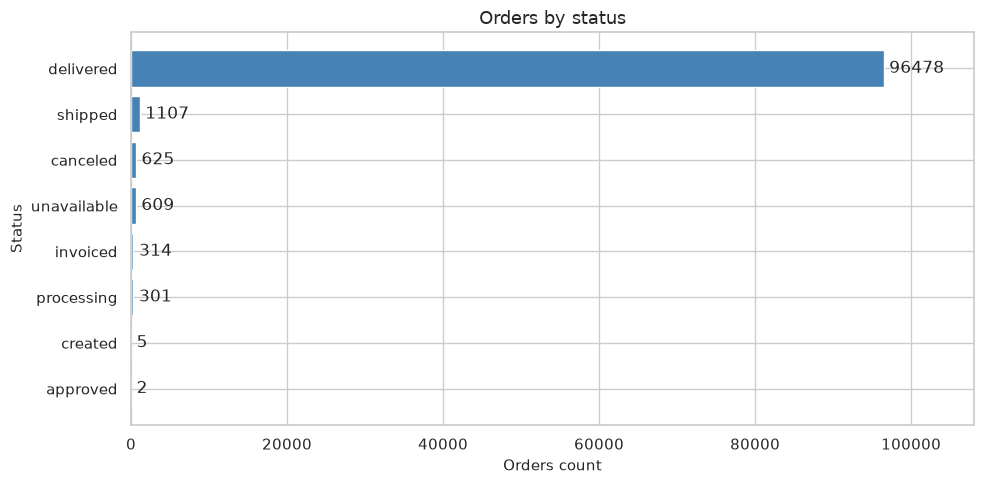

In [60]:
status_counts = (
    orders["order_status"]
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    status_counts.index,
    status_counts.values,
    color="steelblue"
)

ax.bar_label(bars, padding=4)

ax.set_title("Orders by status")
ax.set_xlabel("Orders count")
ax.set_ylabel("Status")
ax.set_xlim(0, status_counts.max() * 1.12)

plt.tight_layout()
plt.show()

The dataset contains 99.441 orders,of witch 96,478 are classified as delivered, representing approximately 97.02% of the records.

This concetration indicates that there is a significant volume of completed orders for training supervised models.

However, not all of these orders have complete temporal information. Therefore, the final selection needs to consider both the status and avaibility of the necessary dates.

The conclusion is the database shows high coverage of delivered orders, but requires filtering and validation of temporal information before modeling.

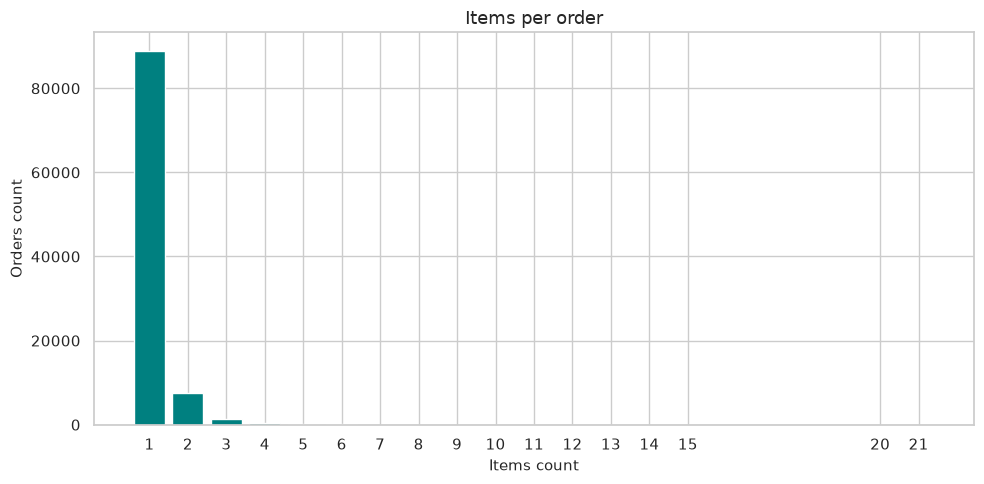

In [61]:
items_distribution = (
    items_per_order
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    items_distribution.index,
    items_distribution.values,
    color="teal"
)

ax.set_title("Items per order")
ax.set_xlabel("Items count")
ax.set_ylabel("Orders count")

ax.set_xticks(items_distribution.index)

plt.tight_layout()
plt.show()

An average of 1.14 items per order, combined with a median and third quartile equal to 1, indicates that most orders contain only one item.

However, there are orders with up to 21 items, highlighting variations in the composition of purchases.

These values ​​should not be automatically considered errors. An order with many items can be legitimate.

Conclusion: the number of items is a potential feature for the models, but it will need to be aggregated by order_id before integration with the main table.

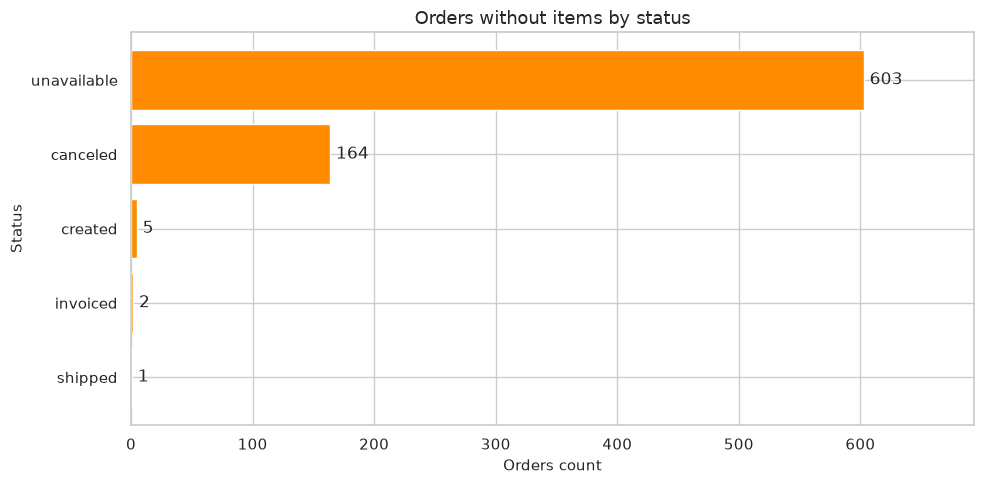

In [62]:
missing_items_status = (
    orders_without_itens["order_status"]
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    missing_items_status.index,
    missing_items_status.values,
    color="darkorange"
)

ax.bar_label(bars, padding=4)

ax.set_title("Orders without items by status")
ax.set_xlabel("Orders count")
ax.set_ylabel("Status")

ax.set_xlim(0, missing_items_status.max() * 1.15)

plt.tight_layout()
plt.show()

Of the 775 orders without items, 603 are classified as unavailable and 164 as canceled.

The remaining records are distributed between created, invoiced and shipped.

None of the orders without items are classified as delivered.

This means that by selecting only delivered orders, these records will be naturally excluded from the initial training population.

Conclusion: the absence of items is concentrated in uncompleted orders. This characteristic must be documented, but does not require imputation of items to the population of delivered orders.

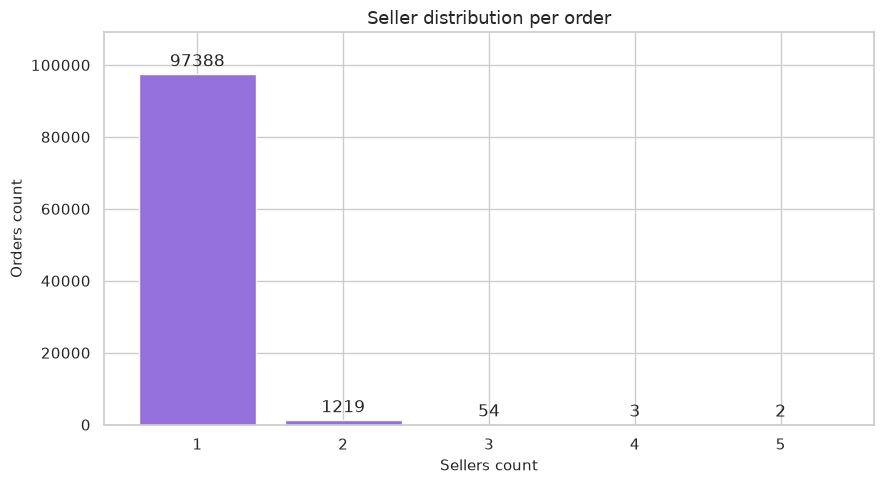

In [64]:
seller_distribution = (
    sellers_per_order
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    seller_distribution.index.astype(str),
    seller_distribution.values,
    color="mediumpurple"
)

ax.bar_label(bars, padding=3)

ax.set_title("Seller distribution per order")
ax.set_xlabel("Sellers count")
ax.set_ylabel("Orders count")

ax.set_ylim(0, seller_distribution.max() * 1.12)

plt.tight_layout()
plt.show()

The dataset shows an average of approximately 1.014 vendors per order with items, with a maximum of five vendors.

Orders with multiple vendors represent approximately 1.30% of the orders present in order_items.

This is relevant for the development of geographic features. An order with multiple vendors may have different shipping origins, making it difficult to calculate a single distance between vendor and consumer.

Conclusion: it will be necessary to define a strategy to represent orders with multiple vendors, such as using the longest distance, the average distance, or other aggregated statistics.

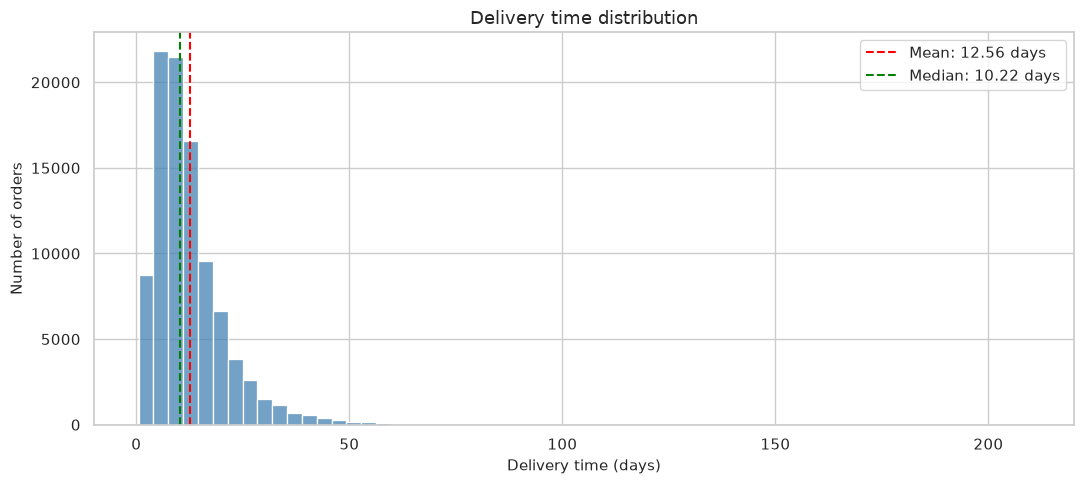

In [68]:
delivery_times = (
    deliverd_orders["delivery_time_days"]
    .dropna()
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    delivery_times,
    bins=60,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    delivery_times.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {delivery_times.mean():.2f} days"
)

ax.axvline(
    delivery_times.median(),
    color="green",
    linestyle="--",
    label=f"Median: {delivery_times.median():.2f} days"
)

ax.set_title("Delivery time distribution")
ax.set_xlabel("Delivery time (days)")
ax.set_ylabel("Number of orders")
ax.legend()

plt.tight_layout()
plt.show()

Initial statistical results show that the average delivery time is greater than the median.

This suggests a right-skewed distribution, in which orders with long delivery times increase the average.

Records with delivery times of up to 209 days were also identified.

It is important to note that extreme values ​​are not necessarily invalid. They may represent real logistical problems or inconsistencies in the records.

Conclusion: Delivery time shows evidence of asymmetry and extreme values ​​that should be investigated before training the regression model.

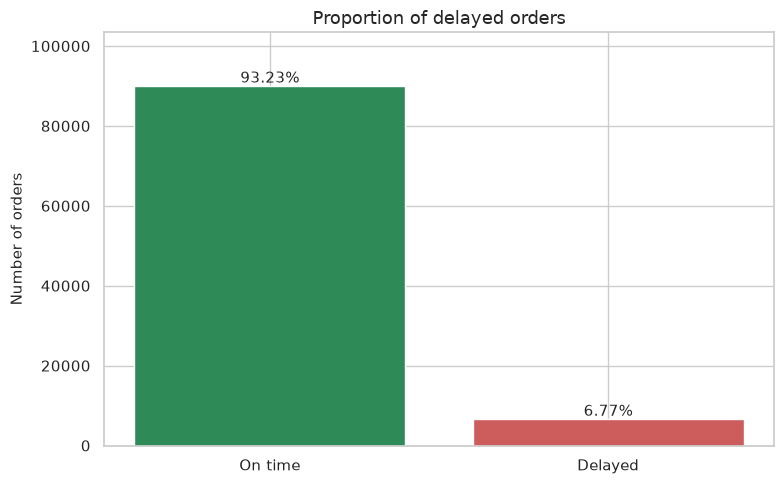

In [72]:
delay_counts = (
    deliverd_orders["is_delayed"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

delay_labels = [
    "On time",
    "Delayed"
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    delay_labels,
    delay_counts.values,
    color=["seagreen", "indianred"]
)

total = delay_counts.sum()

for bar, count in zip(bars, delay_counts.values):
    percentage = count / total * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("Proportion of delayed orders")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, delay_counts.max() * 1.15)

plt.tight_layout()
plt.show()